# Imbalance Experiments

In the previous notebooks, we handled the extreme class imbalance (0.13% fraud) by using algorithm-level penalizations (`class_weight` and `scale_pos_weight`). 

In this notebook, we explore data-level techniques using the `imblearn` library:
1. **Random Under-Sampling**: Reducing the number of legitimate transactions to speed up training and balance the dataset.
2. **SMOTE (Synthetic Minority Over-sampling Technique)**: Generating synthetic fraudulent transactions.

*Note: Running SMOTE on 6.3 million rows would consume an enormous amount of RAM and time. Therefore, we will combine these techniques by first undersampling the majority class to a manageable size, and then applying SMOTE.*

In [1]:
import pandas as pd
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import sys
sys.path.append('..')

from src.preprocessing import load_and_clean_data, preprocess_and_split
from src.feature_engineering import engineer_features
from src.evaluate import evaluate_model

### 1. Load and Prepare Data

In [2]:
data_path = '../data/raw/PS_20174392719_1491204439457_log.csv'
df = load_and_clean_data(data_path)
X_train, X_val, X_test, y_train, y_val, y_test, preprocessor = preprocess_and_split(df, val_size=0.15, test_size=0.15, random_state=42)
print(f"Original training shape: {X_train.shape}")
print(f"Original training fraud count: {y_train.sum()}")

Original training shape: (1939285, 10)
Original training fraud count: 5749


### 1.5 No Handling
Train an XGBoost model without any imbalance handling to serve as a baseline.

--- Evaluation for XGBoost (No Handling) ---


              precision    recall  f1-score   support

           0       1.00      1.00      1.00    414330
           1       0.98      0.99      0.98      1232

    accuracy                           1.00    415562
   macro avg       0.99      0.99      0.99    415562
weighted avg       1.00      1.00      1.00    415562



ROC-AUC: 0.9969
PR-AUC:  0.9883


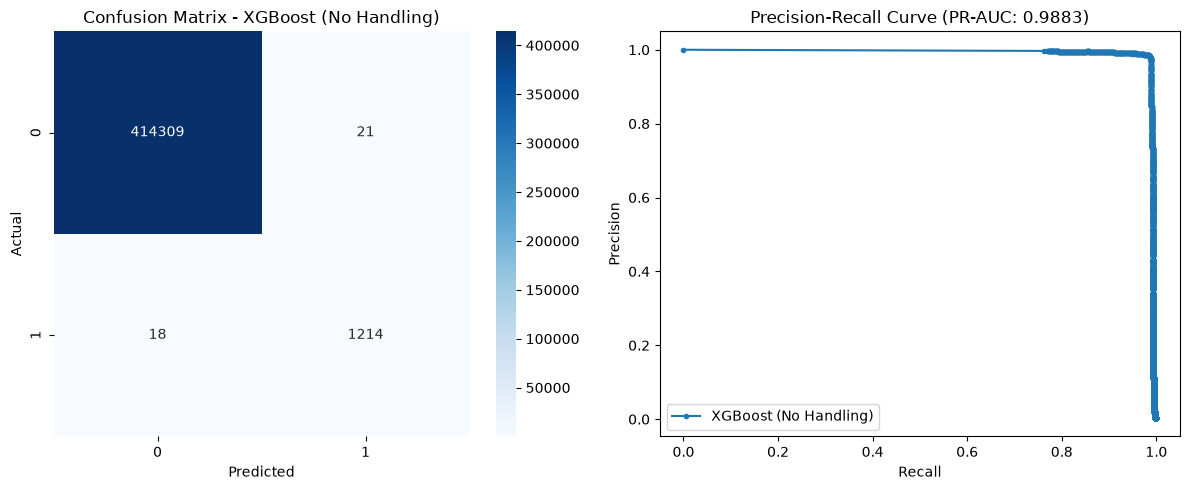

In [3]:
xgb_none = xgb.XGBClassifier(tree_method='hist', max_depth=6, n_estimators=100, random_state=42, n_jobs=-1)
xgb_none.fit(X_train, y_train)
metrics_none = evaluate_model(y_val, xgb_none.predict(X_val), xgb_none.predict_proba(X_val)[:, 1], "XGBoost (No Handling)")

### 1.6 Class Weights
Train using scale_pos_weight.

--- Evaluation for XGBoost (Class Weights) ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    414330
           1       0.98      0.99      0.99      1232

    accuracy                           1.00    415562
   macro avg       0.99      1.00      0.99    415562
weighted avg       1.00      1.00      1.00    415562



ROC-AUC: 0.9994
PR-AUC:  0.9948


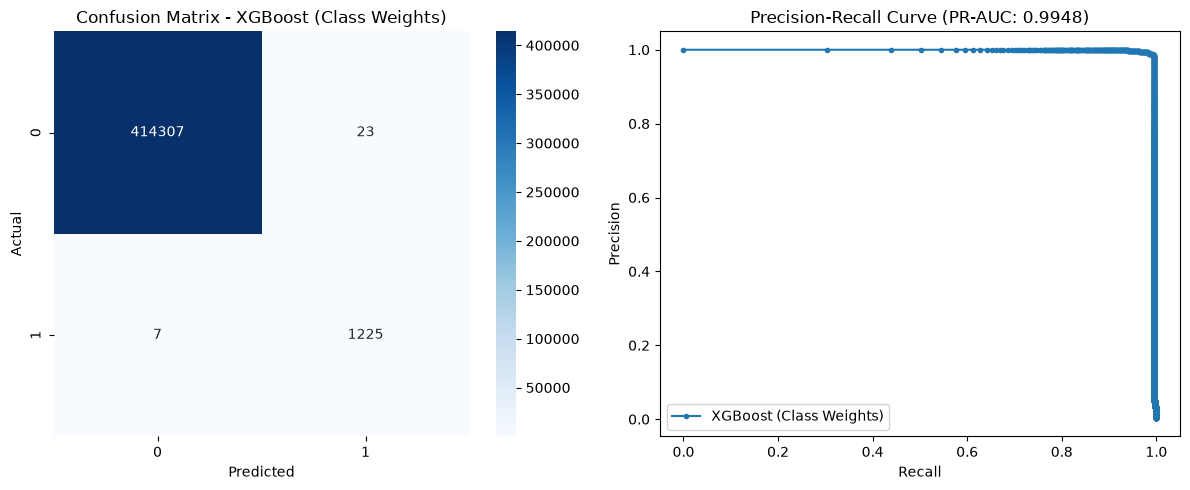

In [4]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_weight = xgb.XGBClassifier(scale_pos_weight=scale_pos_weight, tree_method='hist', max_depth=6, n_estimators=100, random_state=42, n_jobs=-1)
xgb_weight.fit(X_train, y_train)
metrics_weight = evaluate_model(y_val, xgb_weight.predict(X_val), xgb_weight.predict_proba(X_val)[:, 1], "XGBoost (Class Weights)")

### 2. Random Under-Sampling
Let's drastically reduce the majority class (legit transactions). Instead of a 1:1 ratio which might discard too much information, we'll undersample until the minority class makes up 10% of the dataset (`sampling_strategy=0.1`).

In [5]:
under_sampler = RandomUnderSampler(sampling_strategy=0.1, random_state=42)
X_train_under, y_train_under = under_sampler.fit_resample(X_train, y_train)

print(f"Under-sampled training shape: {X_train_under.shape}")
print(f"Under-sampled training fraud count: {y_train_under.sum()}")

Under-sampled training shape: (63239, 10)
Under-sampled training fraud count: 5749


--- Evaluation for XGBoost (Under-sampled) ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    414330
           1       0.91      1.00      0.95      1232

    accuracy                           1.00    415562
   macro avg       0.95      1.00      0.97    415562
weighted avg       1.00      1.00      1.00    415562



ROC-AUC: 0.9988
PR-AUC:  0.9924


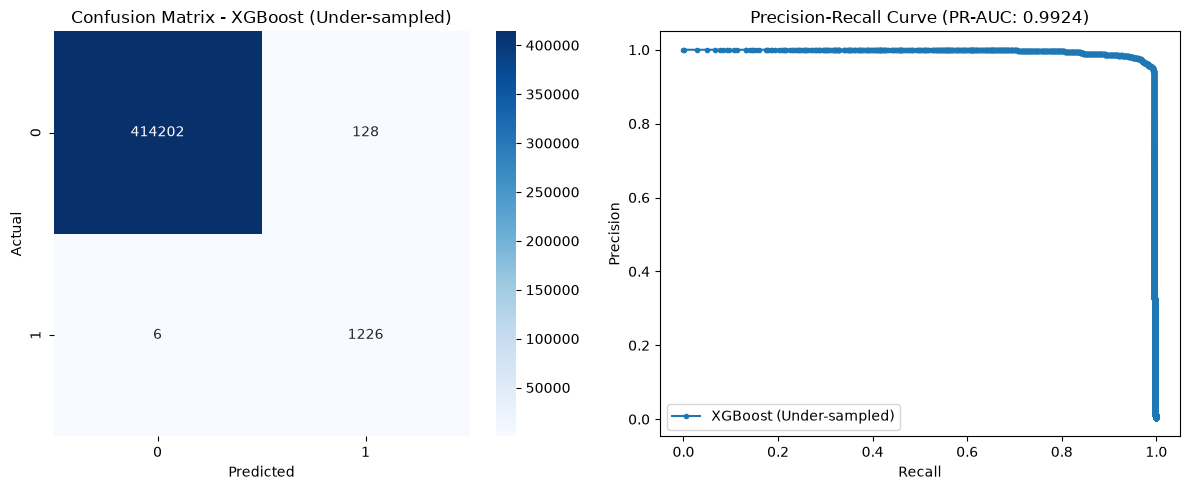

In [6]:
xgb_under = xgb.XGBClassifier(tree_method='hist', max_depth=6, n_estimators=100, random_state=42, n_jobs=-1)
xgb_under.fit(X_train_under, y_train_under)
metrics_under = evaluate_model(y_val, xgb_under.predict(X_val), xgb_under.predict_proba(X_val)[:, 1], "XGBoost (Under-sampled)")

### 3. SMOTE (Combined with Under-Sampling)
Now we'll use SMOTE to bring the ratio up to 1:1 (`sampling_strategy=1.0`), but we apply it **after** the under-sampler to save time.

In [7]:
smote = SMOTE(sampling_strategy=1.0, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_under, y_train_under)

print(f"SMOTE training shape: {X_train_smote.shape}")
print(f"SMOTE training fraud count: {y_train_smote.sum()}")

SMOTE training shape: (114980, 10)
SMOTE training fraud count: 57490


--- Evaluation for XGBoost (SMOTE) ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    414330
           1       0.85      1.00      0.92      1232

    accuracy                           1.00    415562
   macro avg       0.93      1.00      0.96    415562
weighted avg       1.00      1.00      1.00    415562



ROC-AUC: 0.9995
PR-AUC:  0.9914


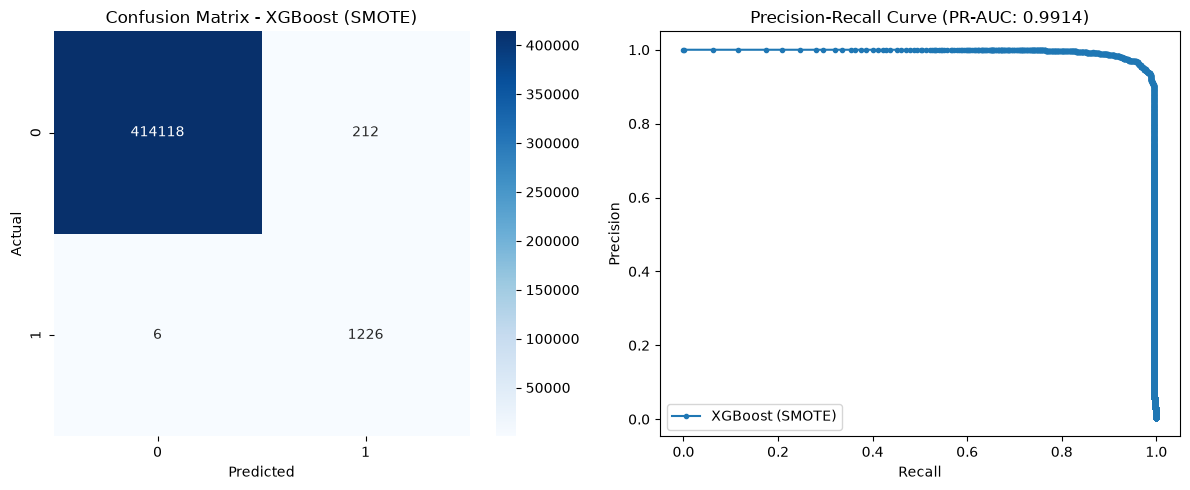

In [8]:
xgb_smote = xgb.XGBClassifier(tree_method='hist', max_depth=6, n_estimators=100, random_state=42, n_jobs=-1)
xgb_smote.fit(X_train_smote, y_train_smote)
metrics_smote = evaluate_model(y_val, xgb_smote.predict(X_val), xgb_smote.predict_proba(X_val)[:, 1], "XGBoost (SMOTE)")

### Summary
Compare the PR-AUC and Recall of these data-level resampling techniques with the algorithm-level techniques from the previous notebook. Often, with powerful models like XGBoost, `scale_pos_weight` on the full dataset yields the best overall performance, but Undersampling offers massive speed benefits!

In [9]:
import json
results = {
    'No Handling': metrics_none,
    'Class Weights': metrics_weight,
    'Undersampling': metrics_under,
    'SMOTE': metrics_smote
}
with open('../reports/imbalance_experiments.json', 'w') as f:
    json.dump(results, f, indent=4)
print("Saved imbalance metrics.")

Saved imbalance metrics.
